# FalkorDB → PyTorch Geometric: a cell graph workflow

**Team question:** Can a graph model recognize local EdU-positive clustering in a lobe when a simple graph query already measures that pattern?

This notebook joins two proof of concepts. **FalkorDB** stores lobe and cell properties and directed nearest-neighbor relationships, computes an interpretable spatial summary, and exports the stored graph. **PyTorch Geometric (PyG)** reads that export, builds one `Data` object per lobe, and trains a graph classifier. The GNN never reads the simulator's arrays directly; the database export is the handoff.

All observations and labels are **synthetic**. “Dpn-like cell” and “EdU-positive” are simulated properties, not measurements or biological findings. A `NEAR` edge means 3D centroid proximity, not a synapse or Vistiq's containment/overlap edge. The target is **one label per lobe**, not a label per cell. The examples are generated in matched pairs with the same geometry, measurements, and EdU-positive count; only which cells receive EdU-positive status changes.

**What we compare:** a global summary as a negative control; a logistic model using FalkorDB's positive-neighbor fraction as a meaningful spatial baseline; and a two-layer GraphSAGE model. Test pairs are held out before any fitting. A GNN must be compared with the spatial baseline before its extra complexity is justified.

## 0. UVA HPC setup

| OOD JupyterLab setting | Request |
| --- | --- |
| Partition | **Interactive** |
| Number of hours | **any** |
| Number of cores | **4** |
| Memory request | **16 GB** |
| Work directory | **HOME** |
| GPU | **None** |
| Kernel | **Python (Vistiq POC)**, pointing to `~/vistiqlab/vistiq/.venv` |

The selected kernel needs `falkordb`, `torch`, `torch_geometric`, `numpy`, `pandas`, `scikit-learn`, and `matplotlib`. These are Python packages **in the kernel**, while the FalkorDB server runs separately in Apptainer. If an import is missing, install it into `~/vistiqlab/vistiq/.venv`, restart the kernel, and rerun. No `.lif` data or Vistiq bundle is required.

In a **JupyterLab Terminal belonging to the same OOD job**, download the server image once (skip the pull if this `.sif` already exists):

```bash
module load apptainer
mkdir -p ~/vistiqlab
apptainer pull ~/vistiqlab/falkordb-server.sif \
  docker://falkordb/falkordb-server:v4.20.6-x64
```

Start FalkorDB in that terminal for each new job. Leave it running while executing the notebook:

```bash
module load apptainer
apptainer exec --cleanenv ~/vistiqlab/falkordb-server.sif \
  redis-server \
  --port 16379 \
  --bind 127.0.0.1 \
  --protected-mode yes \
  --save '' \
  --appendonly no \
  --dir /tmp \
  --loadmodule /var/lib/falkordb/bin/falkordb.so
```

The notebook connects to **`127.0.0.1:16379` on that compute node**. A server in another OOD job or on a login node will not be reachable through `127.0.0.1`. If a second launch says the port is in use, keep the existing server instead. Press **Ctrl+C in the server terminal** to stop it. Saving and append-only logging are disabled; its graphs disappear when the server stops. The host's older glibc prevented the embedded `falkordblite` package from starting in the previous exercise; this notebook uses the working Apptainer server.

In [2]:
import copy
import os
import sys
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from falkordb import FalkorDB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv, global_max_pool, global_mean_pool
from torch_geometric.utils import to_undirected

SEED = 17
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, max(1, int(os.environ.get("SLURM_CPUS_PER_TASK", "4")))))
device = torch.device("cpu")  # No GPU allocation is needed for this small proof of concept.

host = os.environ.get("FALKORDB_HOST", "127.0.0.1")
port = int(os.environ.get("FALKORDB_PORT", "16379"))
db = FalkorDB(host=host, port=port,
              password=os.environ.get("FALKORDB_PASSWORD") or None)
graph_name = "vistiq_db_pyg_" + uuid4().hex[:12]
graph = db.select_graph(graph_name)
try:
    assert graph.query("RETURN 1 AS ready").result_set[0][0] == 1
except Exception as exc:
    raise RuntimeError(
        "Cannot reach FalkorDB. Start Apptainer in a terminal on this same compute node "
        f"and check {host}:{port}."
    ) from exc

print("Kernel Python:", sys.executable)
print("Training device:", device)
print("FalkorDB:", f"{host}:{port}", "graph:", graph_name)
print("PyTorch:", torch.__version__)

Kernel Python: /sfs/gpfs/tardis/home/tqv9uu/vistiqlab/vistiq/.venv/bin/python
Training device: cpu
FalkorDB: 127.0.0.1:16379 graph: vistiq_db_pyg_d0dde08e0c77
PyTorch: 2.11.0+cu128


## 1. Simulate matched lobes

Each pair has a scattered example (`label=0`) and a weakly to moderately clustered example (`label=1`). They share 55–75 cell centroids, measurements, and a 30% EdU-positive rate. We link each cell to its five nearest cells in **3D Euclidean distance**. The clustered partner places a varying fraction of its positive cells near a random anchor. Other positive cells are sampled elsewhere. Some pairs are deliberately hard enough that the positive-neighbor score can rank them incorrectly.

The two labels are known because **we created this simulation**. A real study would need independently defined outcomes at the right biological level; the generated labels cannot establish a biological effect.

Matched pairs: 80 lobes: 160
First pair: cells = 70 ; EdU-positive cells in each = [21, 21]


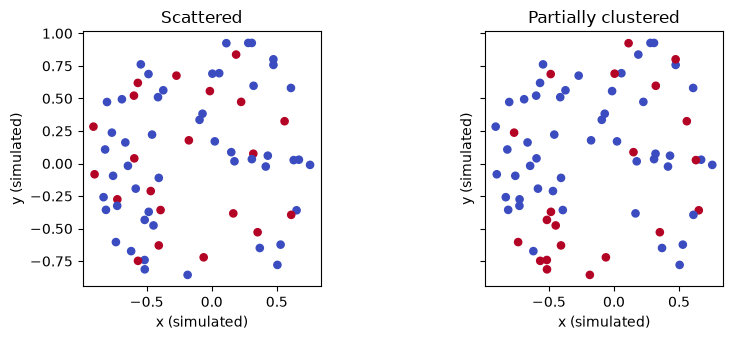

In [3]:
N_PAIRS = 80   # 160 lobe graphs; modest server size for an interactive session.
K = 5
rng = np.random.default_rng(SEED)


def simulate_pair(pair_id, generator):
    n = int(generator.integers(55, 76))
    angles = generator.uniform(0, 2 * np.pi, n)
    radii = np.sqrt(generator.uniform(0.02, 1.0, n))
    positions = np.column_stack((radii * np.cos(angles),
                                 radii * np.sin(angles),
                                 generator.normal(0, 0.12, n))).astype(np.float32)
    log_volume = generator.normal(0, 0.2, n).astype(np.float32)
    dpn_signal = generator.normal(1, 0.15, n).astype(np.float32)

    distances = np.linalg.norm(positions[:, None] - positions[None, :], axis=2)
    np.fill_diagonal(distances, np.inf)
    nearest = np.argsort(distances, axis=1)[:, :K]

    n_positive = round(0.30 * n)
    scattered = np.zeros(n, dtype=np.int64)
    scattered[generator.choice(n, size=n_positive, replace=False)] = 1

    anchor = int(generator.integers(n))
    distance_to_anchor = np.linalg.norm(positions - positions[anchor], axis=1)
    n_core = round(n_positive * generator.uniform(0.10, 0.50))
    core = np.argsort(distance_to_anchor)[:n_core]
    other = generator.choice(np.setdiff1d(np.arange(n), core),
                             size=n_positive - n_core, replace=False)
    clustered = np.zeros(n, dtype=np.int64)
    clustered[np.concatenate((core, other))] = 1

    assert int(scattered.sum()) == int(clustered.sum()) == n_positive
    return dict(pair_id=pair_id, positions=positions, log_volume=log_volume,
                dpn_signal=dpn_signal, nearest=nearest, distances=distances,
                edu=(scattered, clustered))


pairs = [simulate_pair(i, rng) for i in range(N_PAIRS)]
print("Matched pairs:", len(pairs), "lobes:", 2 * len(pairs))
print("First pair: cells =", len(pairs[0]["positions"]),
      "; EdU-positive cells in each =", [int(e.sum()) for e in pairs[0]["edu"]])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True, sharey=True)
for label, ax in enumerate(axes):
    p = pairs[0]
    ax.scatter(p["positions"][:, 0], p["positions"][:, 1],
               c=p["edu"][label], cmap="coolwarm", vmin=0, vmax=1, s=27)
    ax.set(xlabel="x (simulated)", ylabel="y (simulated)",
           title=("Scattered", "Partially clustered")[label])
    ax.set_aspect("equal")
plt.tight_layout()

## 2. Store cells and relationships in FalkorDB

We store `(:Lobe)-[:CONTAINS]->(:Cell)` and a directed `(:Cell)-[:NEAR]->(:Cell)` for each of the `K` closest cells. Lobe properties include `pair_id` and the synthetic `label`, which we retrieve only as the **target**. Cell properties contain EdU status and two simulated measurements; edge distance is stored for later inspection. We create a unique graph name each run so a teammate's graph on a shared server is not overwritten.

Rows are sent to the server in small `UNWIND` batches. For this synthetic exercise, IDs are stable within a run; in real data, the team would need IDs linking segmented objects, image/scene, and region provenance.

In [4]:
lobes, cells, edges = [], [], []
for p in pairs:
    pair_id = p["pair_id"]
    n = len(p["positions"])
    for label in (0, 1):
        lobe_id = f"pair_{pair_id:03d}_{label}"
        lobes.append(dict(id=lobe_id, pair_id=pair_id, label=label))
        for i in range(n):
            cells.append(dict(id=f"{lobe_id}_cell_{i:03d}", lobe_id=lobe_id, idx=i,
                              edu=int(p["edu"][label][i]),
                              log_volume=float(p["log_volume"][i]),
                              dpn_signal=float(p["dpn_signal"][i]),
                              cx=float(p["positions"][i, 0]),
                              cy=float(p["positions"][i, 1]),
                              cz=float(p["positions"][i, 2])))
            for j in p["nearest"][i]:
                edges.append(dict(lobe_id=lobe_id,
                                  src=f"{lobe_id}_cell_{i:03d}",
                                  dst=f"{lobe_id}_cell_{int(j):03d}",
                                  distance=float(p["distances"][i, j])))


def chunks(rows, size=500):
    for start in range(0, len(rows), size):
        yield rows[start:start + size]


if graph.ro_query("MATCH (n) RETURN count(n)").result_set[0][0]:
    raise RuntimeError("The graph already has nodes. Rerun the connection cell for a new graph name.")

graph.query("CREATE INDEX FOR (l:Lobe) ON (l.id)")
graph.query("CREATE INDEX FOR (c:Cell) ON (c.id)")
graph.query("""
    UNWIND $rows AS row
    CREATE (:Lobe {id: row.id, pair_id: row.pair_id, label: row.label})
""", params={"rows": lobes})

for batch_rows in chunks(cells):
    graph.query("""
        UNWIND $rows AS row
        MATCH (l:Lobe {id: row.lobe_id})
        CREATE (c:Cell {id: row.id, idx: row.idx, edu: row.edu,
                        log_volume: row.log_volume, dpn_signal: row.dpn_signal,
                        cx: row.cx, cy: row.cy, cz: row.cz})
        CREATE (l)-[:CONTAINS]->(c)
    """, params={"rows": batch_rows})

for batch_rows in chunks(edges):
    graph.query("""
        UNWIND $rows AS row
        MATCH (a:Cell {id: row.src})
        MATCH (b:Cell {id: row.dst})
        CREATE (a)-[:NEAR {distance: row.distance}]->(b)
    """, params={"rows": batch_rows})

print("Stored", len(lobes), "lobes,", len(cells), "cells,", len(edges), "directed NEAR edges")
assert graph.ro_query("MATCH (l:Lobe) RETURN count(l)").result_set[0][0] == len(lobes)
assert graph.ro_query("MATCH (c:Cell) RETURN count(c)").result_set[0][0] == len(cells)
assert graph.ro_query("MATCH (:Cell)-[r:NEAR]->(:Cell) RETURN count(r)").result_set[0][0] == len(edges)

Stored 160 lobes, 10458 cells, 52290 directed NEAR edges


## 3. An interpretable graph query

For each lobe, the query calculates the fraction of `NEAR` links **from an EdU-positive cell to another EdU-positive cell**:

$$s(G)=\frac{\sum_{(i,j)\in E_{\rm directed}} e_i e_j}{\sum_{(i,j)\in E_{\rm directed}} e_i},$$

where $e_i\in\{0,1\}$ is EdU status and every source cell has exactly five outgoing links. The score is an interpretable spatial baseline, not a ground-truth label. We also query global counts and average measurements. Matched partners have the same global summaries by design.

In [5]:
global_rows = graph.ro_query("""
    MATCH (l:Lobe)-[:CONTAINS]->(c:Cell)
    RETURN l.id, count(c), sum(c.edu), avg(c.log_volume), avg(c.dpn_signal)
""").result_set
global_df = pd.DataFrame(global_rows, columns=[
    "lobe_id", "n_cells", "n_edu", "mean_log_volume", "mean_dpn_signal"
])
global_df["edu_fraction"] = global_df["n_edu"] / global_df["n_cells"]

score_rows = graph.ro_query("""
    MATCH (l:Lobe)-[:CONTAINS]->(a:Cell)-[:NEAR]->(b:Cell)
    RETURN l.id,
           sum(CASE WHEN a.edu = 1 AND b.edu = 1 THEN 1 ELSE 0 END),
           sum(CASE WHEN a.edu = 1 THEN 1 ELSE 0 END)
""").result_set
score_df = pd.DataFrame(score_rows, columns=[
    "lobe_id", "positive_to_positive", "positive_source_slots"
])
summary = global_df.merge(score_df, on="lobe_id", validate="one_to_one")
summary["positive_neighbor_fraction"] = (
    summary["positive_to_positive"] / summary["positive_source_slots"]
)
assert len(summary) == 2 * N_PAIRS
assert (summary["positive_source_slots"] == K * summary["n_edu"]).all()
summary = summary.set_index("lobe_id")
display(summary[["n_cells", "n_edu", "positive_neighbor_fraction"]].head())

,n_cells,n_edu,positive_neighbor_fraction
lobe_id,,,
pair_042_0,60,18.0,0.300000
pair_005_1,60,18.0,0.600000
pair_060_1,62,19.0,0.336842
pair_039_0,75,22.0,0.227273
pair_074_1,71,21.0,0.400000


## 4. Export **the stored graph** to PyTorch Geometric

Two database queries retrieve the cell table and the directed neighbor list. For each lobe, `x` is a float matrix with columns `[edu, log_volume, dpn_signal]`; `edge_index` is a 2-row integer tensor of node indices. PyG gets undirected links for message passing by adding the reverse of each stored directed link. The database score above continues to use the original directed links. `y` is the lobe's synthetic label and `pair_id` is used **only for splitting**, never as model input. `pos` is kept for inspection and is also excluded from the model.

The export is checked against counts and spatial scores from FalkorDB. This check matters: a successful database write alone does not establish that the GNN received the intended edges or features.

In [6]:
from collections import defaultdict

lobe_rows = graph.ro_query("""
    MATCH (l:Lobe)
    RETURN l.id, l.pair_id, l.label
    ORDER BY l.pair_id, l.label
""").result_set
node_rows = graph.ro_query("""
    MATCH (l:Lobe)-[:CONTAINS]->(c:Cell)
    RETURN l.id, c.idx, c.edu, c.log_volume, c.dpn_signal, c.cx, c.cy, c.cz
    ORDER BY l.id, c.idx
""").result_set
edge_rows = graph.ro_query("""
    MATCH (l:Lobe)-[:CONTAINS]->(a:Cell)-[:NEAR]->(b:Cell)
    RETURN l.id, a.idx, b.idx
    ORDER BY l.id, a.idx, b.idx
""").result_set

nodes_by_lobe = defaultdict(list)
edges_by_lobe = defaultdict(list)
for row in node_rows:
    nodes_by_lobe[row[0]].append(row)
for lobe_id, src, dst in edge_rows:
    edges_by_lobe[lobe_id].append((int(src), int(dst)))

pyg_by_id = {}
directed_by_id = {}
for lobe_id, pair_id, label in lobe_rows:
    rows = nodes_by_lobe[lobe_id]
    n = len(rows)
    assert n and [int(row[1]) for row in rows] == list(range(n))
    features = np.array([row[2:5] for row in rows], dtype=np.float32)
    positions = np.array([row[5:8] for row in rows], dtype=np.float32)
    directed = torch.tensor(edges_by_lobe[lobe_id], dtype=torch.long).T.contiguous()
    assert directed.shape == (2, n * K)
    assert torch.all((directed >= 0) & (directed < n))
    directed_by_id[lobe_id] = directed
    pyg_by_id[lobe_id] = Data(
        x=torch.tensor(features), pos=torch.tensor(positions),
        edge_index=to_undirected(directed, num_nodes=n),
        y=torch.tensor([int(label)], dtype=torch.long),
        pair_id=torch.tensor([int(pair_id)], dtype=torch.long),
    )

assert len(pyg_by_id) == len(lobe_rows) == 2 * N_PAIRS
assert sum(g.num_nodes for g in pyg_by_id.values()) == len(node_rows)
assert sum(e.shape[1] for e in directed_by_id.values()) == len(edge_rows)

for lobe_id, g in pyg_by_id.items():
    source, destination = directed_by_id[lobe_id]
    edu = g.x[:, 0]
    numerator = int((edu[source] * edu[destination]).sum().item())
    denominator = int(edu[source].sum().item())
    assert numerator == int(summary.loc[lobe_id, "positive_to_positive"])
    assert denominator == int(summary.loc[lobe_id, "positive_source_slots"])

for i in range(N_PAIRS):
    scattered, clustered = (pyg_by_id[f"pair_{i:03d}_{label}"] for label in (0, 1))
    assert torch.equal(scattered.pos, clustered.pos)
    assert torch.equal(scattered.edge_index, clustered.edge_index)
    assert torch.equal(scattered.x[:, 1:], clustered.x[:, 1:])
    assert scattered.x[:, 0].sum() == clustered.x[:, 0].sum()

print("Exported and checked", len(pyg_by_id), "PyG lobe graphs from FalkorDB")
print("Example:", pyg_by_id["pair_000_0"])

Exported and checked 160 PyG lobe graphs from FalkorDB
Example: Data(x=[70, 3], edge_index=[2, 424], y=[1], pos=[70, 3], pair_id=[1])


## 5. Split by matched pair

We assign **pairs**, rather than cells or individual lobes, to training (60%), validation (20%), or test (20%). Both partners share geometry and measurements; putting one in training and the other in test would leak their shared structure. Only training data fit the models. Validation loss chooses the GNN stopping point. The test split is evaluated once after training.

In [7]:
all_pair_ids = np.arange(N_PAIRS)
train_val_pairs, test_pairs = train_test_split(
    all_pair_ids, test_size=0.20, random_state=SEED
)
train_pairs, val_pairs = train_test_split(
    train_val_pairs, test_size=0.25, random_state=SEED
)
assert not (set(train_pairs) & set(val_pairs) or
            set(train_pairs) & set(test_pairs) or
            set(val_pairs) & set(test_pairs))


def lobe_ids_for(pair_ids):
    return [f"pair_{int(i):03d}_{label}" for i in pair_ids for label in (0, 1)]


train_ids, val_ids, test_ids = (lobe_ids_for(ids) for ids in
                                (train_pairs, val_pairs, test_pairs))
train_graphs, val_graphs, test_graphs = (
    [pyg_by_id[lobe_id] for lobe_id in ids] for ids in (train_ids, val_ids, test_ids)
)
train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=64, shuffle=False)
test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)

for name, ids in (("train", train_pairs), ("validation", val_pairs), ("test", test_pairs)):
    print(f"{name}: {len(ids)} pairs / {2 * len(ids)} lobes")

train: 48 pairs / 96 lobes
validation: 16 pairs / 32 lobes
test: 16 pairs / 32 lobes


## 6. Compare two baselines

- **Global negative control:** A logistic regression uses only cell count, EdU fraction, and mean cell measurements. Both members of a matched pair have identical global values. Pair ranking should be 0.5 by construction.
- **Spatial baseline:** A second logistic regression adds the FalkorDB positive-neighbor fraction. This is a real competitor for the GNN, since it directly encodes the pattern used to generate the class.

Both baselines are fitted **only on training lobes**. The spatial statistic is measured from the same database graph later exported to PyG; it is not supplied to the GNN as a feature.

In [8]:
global_columns = ["n_cells", "edu_fraction", "mean_log_volume", "mean_dpn_signal"]
spatial_columns = global_columns + ["positive_neighbor_fraction"]
# Compare partner summaries by explicit IDs; database rows have no guaranteed order.
for i in range(N_PAIRS):
    a, b = (summary.loc[f"pair_{i:03d}_{label}", global_columns].to_numpy(dtype=float)
            for label in (0, 1))
    assert np.allclose(a, b, atol=1e-6)


def targets(ids):
    return np.array([int(pyg_by_id[lobe_id].y.item()) for lobe_id in ids])


baselines = {}
for name, columns in (("Global negative control", global_columns),
                      ("FalkorDB spatial score", spatial_columns)):
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=1000, random_state=SEED))
    model.fit(summary.loc[train_ids, columns], targets(train_ids))
    baselines[name] = (model, columns)
    val_probabilities = model.predict_proba(summary.loc[val_ids, columns])[:, 1]
    print(f"{name}: validation accuracy = "
          f"{accuracy_score(targets(val_ids), val_probabilities >= 0.5):.3f}")

Global negative control: validation accuracy = 0.500
FalkorDB spatial score: validation accuracy = 0.750


## 7. Train a graph classifier with PyG

`SAGEConv` updates each cell using its features and aggregated neighbor features. Two layers allow information to propagate over a wider local neighborhood. Mean and max pooling turn all updated cell vectors into **one vector per lobe**, which the linear layer maps to a logit for class 1. The loss compares that lobe-level logit with the lobe-level label.

The GNN sees only `batch.x` and `batch.edge_index`; it does **not** see `pair_id`, `pos`, the label as an input feature, or the Cypher spatial score. This notebook fixes the architecture in advance, uses one seed, and selects the stopping epoch using validation loss. Scores on a synthetic test are a workflow check, not a claim that the model generalizes to images or real animals.

Stopped after 63 epochs; restored epoch 51 with validation loss 0.4397


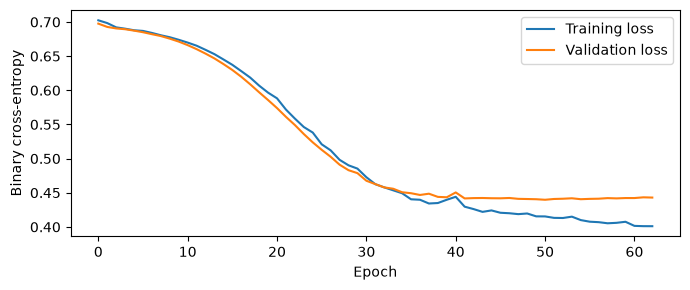

In [9]:
class LobeSAGE(torch.nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.conv1 = SAGEConv(3, hidden)
        self.conv2 = SAGEConv(hidden, hidden)
        self.head = torch.nn.Linear(2 * hidden, 1)

    def forward(self, batch):
        h = F.relu(self.conv1(batch.x, batch.edge_index))
        h = F.relu(self.conv2(h, batch.edge_index))
        pooled = torch.cat((global_mean_pool(h, batch.batch),
                            global_max_pool(h, batch.batch)), dim=1)
        return self.head(pooled).view(-1)


model = LobeSAGE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-4)


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    predictions, labels = [], []
    for batch in loader:
        batch = batch.to(device)
        predictions.append(model(batch).cpu())
        labels.append(batch.y.cpu())
    return torch.cat(predictions), torch.cat(labels)


history = {"training": [], "validation": []}
best_loss, best_epoch, best_weights = float("inf"), 0, None
for epoch in range(1, 91):
    model.train()
    total_loss = 0.0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        loss = F.binary_cross_entropy_with_logits(model(batch), batch.y.float())
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs

    val_logits, val_labels = predict_logits(model, val_loader)
    val_loss = F.binary_cross_entropy_with_logits(val_logits, val_labels.float()).item()
    history["training"].append(total_loss / len(train_graphs))
    history["validation"].append(val_loss)
    if val_loss < best_loss - 1e-4:
        best_loss, best_epoch = val_loss, epoch
        best_weights = copy.deepcopy(model.state_dict())
    if epoch - best_epoch >= 12:
        break

model.load_state_dict(best_weights)
print("Stopped after", epoch, "epochs; restored epoch", best_epoch,
      "with validation loss", round(best_loss, 4))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(history["training"], label="Training loss")
ax.plot(history["validation"], label="Validation loss")
ax.set(xlabel="Epoch", ylabel="Binary cross-entropy")
ax.legend()
plt.tight_layout()

## 8. Evaluate the held-out matched pairs

Accuracy is the fraction of **test lobes** classified correctly; ROC AUC measures ranking across the held-out lobes. Pair ranking is the fraction of test pairs where the clustered lobe receives a higher class-1 probability than its scattered partner (ties count as half). The global negative control should give ties. The spatial baseline shows whether the GNN offers value beyond a transparent neighbor count. The test set has only 16 pairs, so scores are sensitive to sampling and training variation.

In [10]:
test_truth = targets(test_ids)
assert np.array_equal(test_truth, np.tile([0, 1], len(test_pairs)))


def evaluate(name, probabilities):
    predicted = (probabilities >= 0.5).astype(int)
    differences = probabilities[1::2] - probabilities[0::2]
    pair_ranking = np.mean(np.where(differences > 1e-10, 1.0,
                                    np.where(differences < -1e-10, 0.0, 0.5)))
    return {"model": name,
            "accuracy": accuracy_score(test_truth, predicted),
            "roc_auc": roc_auc_score(test_truth, probabilities),
            "pair_ranking": pair_ranking}


results = []
for name, (baseline, columns) in baselines.items():
    probabilities = baseline.predict_proba(summary.loc[test_ids, columns])[:, 1]
    results.append(evaluate(name, probabilities))

logits, labels = predict_logits(model, test_loader)
assert np.array_equal(labels.numpy(), test_truth)
gnn_probabilities = torch.sigmoid(logits).numpy()
results.append(evaluate("GraphSAGE (database export)", gnn_probabilities))
display(pd.DataFrame(results).round(3))
print("GraphSAGE confusion matrix (rows: true 0/1; columns: predicted 0/1):")
print(confusion_matrix(test_truth, gnn_probabilities >= 0.5, labels=[0, 1]))

,model,accuracy,roc_auc,pair_ranking
0,Global negative control,0.500,0.500,0.500
1,FalkorDB spatial score,0.781,0.799,0.844
2,GraphSAGE (database export),0.875,0.922,0.938


GraphSAGE confusion matrix (rows: true 0/1; columns: predicted 0/1):
[[14  2]
 [ 2 14]]


## 9. Diagnostic and next steps

We can shuffle EdU indicators **within each held-out lobe**, keeping each lobe's positive count, edges, and other properties unchanged. This destroys much of the local signal. A reduced GNN pair ranking is consistent with reliance on spatial organization, but this transformed set is outside the original data-generating process; it is a diagnostic, not another test score.

For Vistiq data, the database handoff could eventually store segmented object IDs, scene IDs, coordinates with physical units, measured intensity/shape features, region membership, and a clearly documented edge rule. An independent animal/lobe outcome and **animal-level train/test split** would be needed for a real prediction task. The transparent FalkorDB statistic should remain a comparator, and simple in-memory graphs may suffice if database search and persistence are not needed.

API references: [FalkorDB Python client](https://falkordb-py.readthedocs.io/en/latest/falkordb.html) and [PyTorch Geometric documentation](https://pytorch-geometric.readthedocs.io/en/latest/).

In [11]:
shuffle_rng = np.random.default_rng(SEED + 1000)
shuffled = []
for original in test_graphs:
    changed = original.clone()
    permutation = torch.tensor(shuffle_rng.permutation(original.num_nodes), dtype=torch.long)
    changed.x[:, 0] = original.x[permutation, 0]
    shuffled.append(changed)

shuffled_logits, shuffled_labels = predict_logits(
    model, DataLoader(shuffled, batch_size=64, shuffle=False)
)
assert np.array_equal(shuffled_labels.numpy(), test_truth)
diagnostic = evaluate("Shuffled EdU diagnostic", torch.sigmoid(shuffled_logits).numpy())
print("Pair ranking after shuffling:", round(diagnostic["pair_ranking"], 3))

# Optional after review: delete only this notebook's uniquely named database graph.
# graph.delete()

Pair ranking after shuffling: 0.5
